--- 4. Kernel Evaluation ---
Accuracy with 'linear' kernel: 66.67%
Accuracy with 'poly' kernel: 100.00%
Accuracy with 'rbf' kernel: 100.00%

--- 5. Hyperparameter Tuning ---
Optimal Parameters: {'C': 10, 'gamma': 0.1}
Tuned RBF Model Test Accuracy: 100.00%


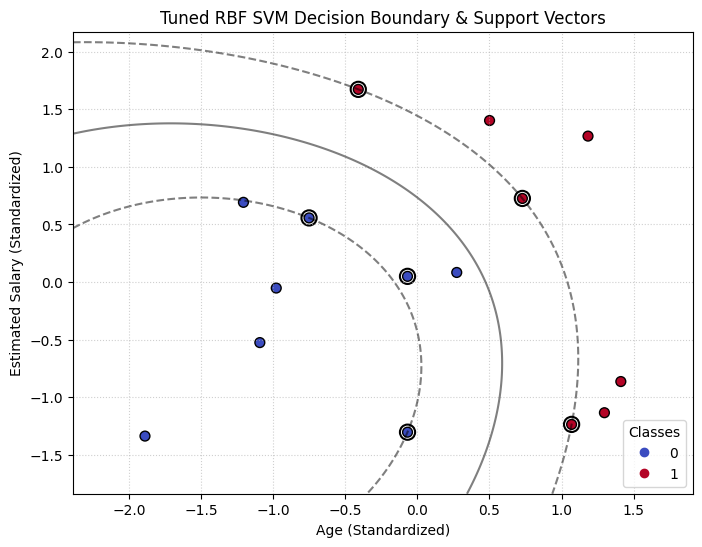

In [8]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

csv_data = """Age,EstimatedSalary,Purchased
19,19000,0
35,20000,0
26,43000,0
27,57000,0
32,108000,1
25,79000,0
46,96000,1
48,33000,1
45,22000,1
35,60000,0
38,61000,0
42,80000,1
47,25000,1
29,75000,0
40,100000,1"""


df = pd.read_csv(io.StringIO(csv_data))
X = df[['Age', 'EstimatedSalary']].values
y = df['Purchased'].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

kernels = ['linear', 'poly', 'rbf']
print("--- 4. Kernel Evaluation ---")
for k in kernels:
    model = SVC(kernel=k, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"Accuracy with '{k}' kernel: {acc * 100:.2f}%")

print("\n--- 5. Hyperparameter Tuning ---")
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': [0.1, 1, 10]
}

grid_search = GridSearchCV(SVC(kernel='rbf', random_state=42), param_grid, cv=2)
grid_search.fit(X_train, y_train)

best_svc = grid_search.best_estimator_
print(f"Optimal Parameters: {grid_search.best_params_}")

tuned_pred = best_svc.predict(X_test)
tuned_acc = accuracy_score(y_test, tuned_pred)
print(f"Tuned RBF Model Test Accuracy: {tuned_acc * 100:.2f}%")

def plot_svc_decision_boundary(model, X, y, title):
    plt.figure(figsize=(8, 6))

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500),
                         np.linspace(y_min, y_max, 500))

    Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contour(xx, yy, Z, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])

    scatter = plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='k', s=50)

    plt.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], s=120,
                facecolors='none', edgecolors='black', linewidths=1.5, label='Support Vectors')

    plt.title(title)
    plt.xlabel('Age (Standardized)')
    plt.ylabel('Estimated Salary (Standardized)')
    plt.legend(*scatter.legend_elements(), loc="lower right", title="Classes")
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.show()

plot_svc_decision_boundary(best_svc, X_scaled, y, "Tuned RBF SVM Decision Boundary & Support Vectors")
